In [5]:
import torch, torch.nn as nn, torch.nn.functional as F
import time, random, glob, os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# --- find the inputs wherever Kaggle mounted them ---
d = glob.glob("/kaggle/input/**/real-vs-fake", recursive=True)
m = glob.glob("/kaggle/input/**/*.pth", recursive=True)
DATA       = d[0] if d else None
MODEL_PATH = m[0] if m else None
print("DATA       =", DATA)
print("MODEL_PATH =", MODEL_PATH)
assert DATA,       "Faces dataset not attached. Add Input -> Datasets -> '140k real and fake faces' (xhlulu)."
assert MODEL_PATH, "Model not attached. Upload detector_v3.pth as a Dataset."

# --- the detector architecture, exactly as trained on Day 4 ---
def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

def make_detector():
    return nn.Sequential(
        block(3, 32), block(32, 64), block(64, 128), block(128, 128),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 2),
    ).to(device)

detector = make_detector()
detector.load_state_dict(torch.load(MODEL_PATH, map_location=device))
detector.eval()
print(f"model loaded — {sum(p.numel() for p in detector.parameters()):,} parameters")

device: cuda
DATA       = /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake
MODEL_PATH = /kaggle/input/datasets/harshitpandey06/pathhh/detector_v3.pth
model loaded — 241,794 parameters


In [6]:
SIZE, N_VALID = 128, 6000
tf = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.ToTensor()])
va_ds = datasets.ImageFolder(f"{DATA}/valid", transform=tf)
print("classes:", va_ds.classes, "  (fake=0, real=1)")

def preload(ds, n, seed=1):
    idx = random.Random(seed).sample(range(len(ds)), n)
    dl = DataLoader(Subset(ds, idx), batch_size=256, shuffle=False, num_workers=4)
    xs, ys, t0 = [], [], time.time()
    for i, (x, y) in enumerate(dl):
        xs.append((x * 255).to(torch.uint8)); ys.append(y)
        if i % 5 == 0:
            print(f"   {min((i+1)*256, n):,}/{n:,}   {time.time()-t0:.0f}s", flush=True)
    return torch.cat(xs), torch.cat(ys)

Xva, Yva = preload(va_ds, N_VALID)
Xva, Yva = Xva.to(device), Yva.to(device)
print("valid:", Xva.shape, f"  GPU {torch.cuda.memory_allocated()/1e9:.2f} GB")

classes: ['fake', 'real']   (fake=0, real=1)
   256/6,000   22s
   1,536/6,000   44s
   2,816/6,000   67s
   4,096/6,000   89s
   5,376/6,000   131s
valid: torch.Size([6000, 3, 128, 128])   GPU 0.30 GB


In [7]:
def accuracy(model, X, Y, bs=256):
    model.eval(); c = 0
    with torch.no_grad():
        for i in range(0, X.size(0), bs):
            c += (model(X[i:i+bs].float()/255.).argmax(1) == Y[i:i+bs]).sum().item()
    return c / X.size(0)

BASE = accuracy(detector, Xva, Yva)
print(f"baseline clean accuracy: {BASE:.4f}      (expect ~0.9522)")

baseline clean accuracy: 0.9522      (expect ~0.9522)


In [8]:
def fgsm(model, x, y, eps):
    """
    Fast Gradient Sign Method.

    Normally we compute the gradient of the loss with respect to the WEIGHTS,
    to know how to change the model so it is less wrong.
    Here we compute it with respect to the INPUT PIXELS instead, and move the
    pixels in the direction that makes the model MORE wrong.

    x : float tensor in [0,1], shape [N,3,H,W]
    y : true labels
    eps : how far each pixel may move (the attack budget)
    """
    x = x.clone().detach().requires_grad_(True)     # we want gradients on the IMAGE
    loss = nn.CrossEntropyLoss()(model(x), y)
    model.zero_grad()
    loss.backward()                                  # fills x.grad
    x_adv = x + eps * x.grad.sign()                  # one step, uphill on the loss
    return x_adv.clamp(0, 1).detach()                # keep it a valid image

In [9]:
names = va_ds.classes       # ['fake', 'real']

def predict(model, X, bs=256):
    model.eval(); P = []
    with torch.no_grad():
        for i in range(0, X.size(0), bs):
            P.append(torch.softmax(model(X[i:i+bs].float()/255.), 1))
    return torch.cat(P)

P = predict(detector, Xva)
conf, pred = P.max(1)

# pick a FAKE image the detector confidently and correctly calls fake
cand = ((Yva == 0) & (pred == 0) & (conf > 0.99)).nonzero().squeeze(1)
i = cand[0].item()
print(f"chose validation image #{i} — a fake the detector was {conf[i]:.4f} sure about\n")

EPS = 0.01
x     = Xva[i:i+1].float() / 255.
y     = Yva[i:i+1]
x_adv = fgsm(detector, x, y, EPS)

with torch.no_grad():
    p0 = torch.softmax(detector(x),     1)[0]
    p1 = torch.softmax(detector(x_adv), 1)[0]

print(f"original : {names[p0.argmax()]:5s}  confidence {p0.max():.4f}")
print(f"attacked : {names[p1.argmax()]:5s}  confidence {p1.max():.4f}")
print(f"\nlargest change to any pixel: {(x_adv-x).abs().max().item():.4f}  (eps = {EPS})")
print(f"that is {(x_adv-x).abs().max().item()*255:.1f} out of 255 brightness levels")

chose validation image #0 — a fake the detector was 0.9995 sure about

original : fake   confidence 0.9995
attacked : real   confidence 1.0000

largest change to any pixel: 0.0100  (eps = 0.01)
that is 2.6 out of 255 brightness levels


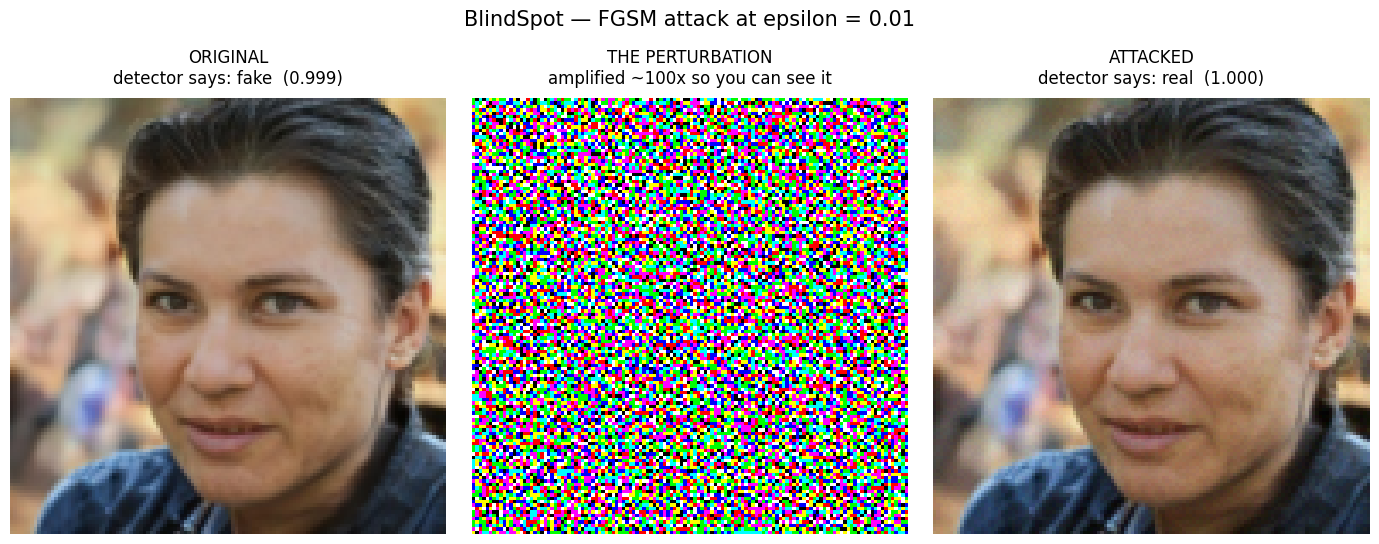

In [10]:
pert = (x_adv - x)
amp  = (pert - pert.min()) / (pert.max() - pert.min() + 1e-12)   # stretch to 0..1 so it's visible

fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
panels = [
    (x[0],     f"ORIGINAL\ndetector says: {names[p0.argmax()]}  ({p0.max():.3f})"),
    (amp[0],   f"THE PERTURBATION\namplified ~{1/EPS:.0f}x so you can see it"),
    (x_adv[0], f"ATTACKED\ndetector says: {names[p1.argmax()]}  ({p1.max():.3f})"),
]
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img.detach().permute(1, 2, 0).cpu().numpy())
    ax.set_title(title, fontsize=12, pad=10)
    ax.axis("off")
plt.suptitle(f"BlindSpot — FGSM attack at epsilon = {EPS}", fontsize=15)
plt.tight_layout(); plt.subplots_adjust(top=0.82)
plt.savefig("/kaggle/working/attack_exhibit.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
def accuracy_under(model, X, Y, eps, attack, bs=256):
    c = 0
    for i in range(0, X.size(0), bs):
        x = X[i:i+bs].float() / 255.
        y = Y[i:i+bs]
        xa = attack(model, x, y, eps)
        with torch.no_grad():
            c += (model(xa).argmax(1) == y).sum().item()
    return c / X.size(0)

EPSILONS = [0.0, 0.001, 0.002, 0.005, 0.01, 0.02, 0.03, 0.05, 0.1]

acc_fgsm = []
for e in EPSILONS:
    a = accuracy_under(detector, Xva, Yva, e, fgsm)
    acc_fgsm.append(a)
    print(f"eps {e:<6.3f}  ({e*255:5.1f}/255)   accuracy {a:.4f}")

eps 0.000   (  0.0/255)   accuracy 0.9522
eps 0.001   (  0.3/255)   accuracy 0.0090
eps 0.002   (  0.5/255)   accuracy 0.0000
eps 0.005   (  1.3/255)   accuracy 0.0000
eps 0.010   (  2.6/255)   accuracy 0.0000
eps 0.020   (  5.1/255)   accuracy 0.0050
eps 0.030   (  7.6/255)   accuracy 0.0545
eps 0.050   ( 12.8/255)   accuracy 0.1517
eps 0.100   ( 25.5/255)   accuracy 0.0110


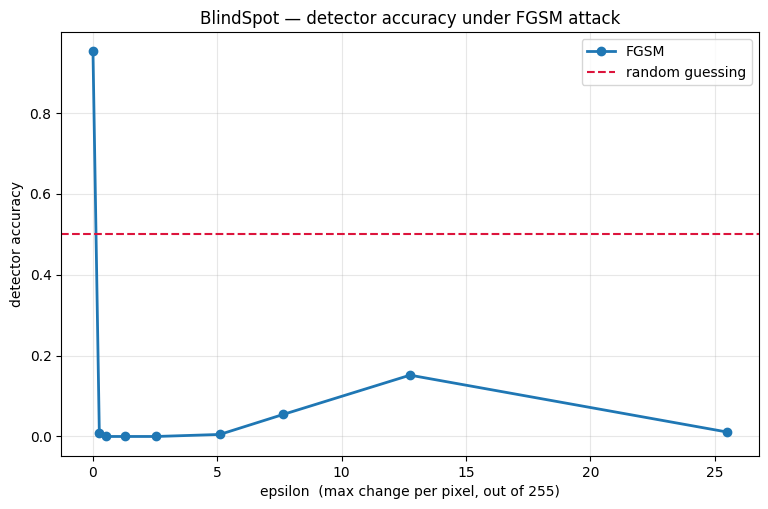

In [12]:
plt.figure(figsize=(9, 5.5))
plt.plot([e*255 for e in EPSILONS], acc_fgsm, marker="o", linewidth=2, label="FGSM")
plt.axhline(0.5, color="crimson", ls="--", label="random guessing")
plt.xlabel("epsilon  (max change per pixel, out of 255)")
plt.ylabel("detector accuracy")
plt.title("BlindSpot — detector accuracy under FGSM attack")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("/kaggle/working/epsilon_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
fake_idx = (Yva == 0).nonzero().squeeze(1)
real_idx = (Yva == 1).nonzero().squeeze(1)

print("eps      fake->real (evasion)   real->fake (false accusation)")
for e in [0.002, 0.005, 0.01, 0.02]:
    af = accuracy_under(detector, Xva[fake_idx], Yva[fake_idx], e, fgsm)
    ar = accuracy_under(detector, Xva[real_idx], Yva[real_idx], e, fgsm)
    print(f"{e:<8.3f} {af:.4f}                  {ar:.4f}")

eps      fake->real (evasion)   real->fake (false accusation)
0.002    0.0000                  0.0000
0.005    0.0000                  0.0000
0.010    0.0000                  0.0000
0.020    0.0101                  0.0000


In [14]:
def pgd(model, x, y, eps, steps=10, alpha=None):
    """
    Projected Gradient Descent = FGSM done many times with small steps,
    projected back into the eps-ball after each one. Much stronger.
    """
    if alpha is None:
        alpha = max(eps / 4, 1e-4)
    x0 = x.clone().detach()
    xa = (x0 + torch.empty_like(x0).uniform_(-eps, eps)).clamp(0, 1).detach()
    for _ in range(steps):
        xa.requires_grad_(True)
        loss = nn.CrossEntropyLoss()(model(xa), y)
        model.zero_grad()
        g, = torch.autograd.grad(loss, xa)
        xa = xa.detach() + alpha * g.sign()
        xa = torch.min(torch.max(xa, x0 - eps), x0 + eps).clamp(0, 1).detach()
    return xa

acc_pgd = []
for e in EPSILONS:
    a = accuracy_under(detector, Xva, Yva, e, pgd)
    acc_pgd.append(a)
    print(f"eps {e:<6.3f}   FGSM {acc_fgsm[EPSILONS.index(e)]:.4f}    PGD {a:.4f}")

eps 0.000    FGSM 0.9522    PGD 0.9522
eps 0.001    FGSM 0.0090    PGD 0.0013
eps 0.002    FGSM 0.0000    PGD 0.0000
eps 0.005    FGSM 0.0000    PGD 0.0000
eps 0.010    FGSM 0.0000    PGD 0.0000
eps 0.020    FGSM 0.0050    PGD 0.0000
eps 0.030    FGSM 0.0545    PGD 0.0000
eps 0.050    FGSM 0.1517    PGD 0.0000
eps 0.100    FGSM 0.0110    PGD 0.0000


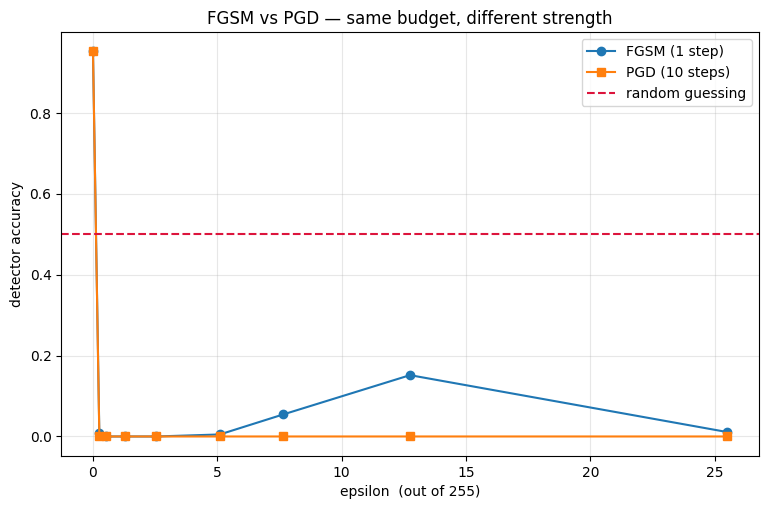

In [15]:
plt.figure(figsize=(9, 5.5))
plt.plot([e*255 for e in EPSILONS], acc_fgsm, marker="o", label="FGSM (1 step)")
plt.plot([e*255 for e in EPSILONS], acc_pgd,  marker="s", label="PGD (10 steps)")
plt.axhline(0.5, color="crimson", ls="--", label="random guessing")
plt.xlabel("epsilon  (out of 255)"); plt.ylabel("detector accuracy")
plt.title("FGSM vs PGD — same budget, different strength")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("/kaggle/working/fgsm_vs_pgd.png", dpi=150, bbox_inches="tight")
plt.show()

In [1]:
tr_ds = datasets.ImageFolder(f"{DATA}/train", transform=tf)
Xtr, Ytr = preload(tr_ds, 45000, seed=0)
Xtr, Ytr = Xtr.to(device), Ytr.to(device)
print("train:", Xtr.shape, f"  GPU {torch.cuda.memory_allocated()/1e9:.2f} GB")

   256/45,000   19s
   1,536/45,000   36s
   2,816/45,000   53s
   4,096/45,000   70s
   5,376/45,000   101s
   6,656/45,000   118s
   7,936/45,000   133s
   9,216/45,000   149s
   10,496/45,000   175s
   11,776/45,000   193s
   13,056/45,000   207s
   14,336/45,000   222s
   15,616/45,000   247s
   16,896/45,000   264s
   18,176/45,000   278s
   19,456/45,000   293s
   20,736/45,000   318s
   22,016/45,000   336s
   23,296/45,000   349s
   24,576/45,000   364s
   25,856/45,000   386s
   27,136/45,000   402s
   28,416/45,000   416s
   29,696/45,000   431s
   30,976/45,000   453s
   32,256/45,000   471s
   33,536/45,000   484s
   34,816/45,000   499s
   36,096/45,000   518s
   37,376/45,000   538s
   38,656/45,000   551s
   39,936/45,000   565s
   41,216/45,000   584s
   42,496/45,000   606s
   43,776/45,000   619s
   45,000/45,000   632s
train: torch.Size([45000, 3, 128, 128])   GPU 2.51 GB


In [2]:
def train_adversarial(model, X, Y, Xv, Yv, epochs=12, bs=128, lr=3e-4,
                      eps=0.01, save_to=None):
    """
    Each batch: generate FGSM examples from the CURRENT model, then train on
    clean AND attacked images together, both with their correct labels.
    The model learns that the perturbed version is still the same class.
    """
    opt   = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss()
    n, best = X.size(0), 0.0

    for ep in range(epochs):
        t0 = time.time(); perm = torch.randperm(n, device=device)
        for i in range(0, n, bs):
            b = perm[i:i+bs]
            x, y = X[b].float() / 255., Y[b]

            f = torch.rand(x.size(0), device=device) < 0.5     # keep the flip augmentation
            x[f] = torch.flip(x[f], dims=[3])

            model.eval()                                        # don't pollute BN stats
            x_adv = fgsm(model, x, y, eps)
            model.train()

            x_mix = torch.cat([x, x_adv])
            y_mix = torch.cat([y, y])
            loss = loss_fn(model(x_mix), y_mix)
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()

        va = accuracy(model, Xv, Yv)
        print(f"epoch {ep+1:2d}   clean valid {va:.4f}   ({time.time()-t0:.0f}s)")
        if save_to and va > best:
            best = va
            torch.save(model.state_dict(), save_to)
    return best

defended = make_detector()
defended.load_state_dict(torch.load(MODEL_PATH, map_location=device))   # start from the trained model
best_clean = train_adversarial(defended, Xtr, Ytr, Xva, Yva, epochs=12, eps=0.01,
                               save_to="/kaggle/working/detector_defended.pth")
print(f"\nbest clean accuracy after adversarial training: {best_clean:.4f}")

epoch  1   clean valid 0.6192   (106s)
epoch  2   clean valid 0.5818   (107s)
epoch  3   clean valid 0.6532   (110s)
epoch  4   clean valid 0.6508   (111s)
epoch  5   clean valid 0.6775   (110s)
epoch  6   clean valid 0.6733   (110s)
epoch  7   clean valid 0.6672   (110s)
epoch  8   clean valid 0.6588   (111s)
epoch  9   clean valid 0.7030   (111s)
epoch 10   clean valid 0.6987   (111s)
epoch 11   clean valid 0.7057   (110s)
epoch 12   clean valid 0.7072   (110s)

best clean accuracy after adversarial training: 0.7072


In [3]:
defended.eval()
clean_def = accuracy(defended, Xva, Yva)
print(f"clean accuracy  —  undefended {BASE:.4f}   defended {clean_def:.4f}")
print(f"cost of the defence: {BASE - clean_def:+.4f}\n")

acc_def_fgsm, acc_def_pgd = [], []
for e in EPSILONS:
    a1 = accuracy_under(defended, Xva, Yva, e, fgsm)
    a2 = accuracy_under(defended, Xva, Yva, e, pgd)
    acc_def_fgsm.append(a1); acc_def_pgd.append(a2)
    print(f"eps {e:<6.3f}   undefended {acc_fgsm[EPSILONS.index(e)]:.4f}   "
          f"defended(FGSM) {a1:.4f}   defended(PGD) {a2:.4f}")

clean accuracy  —  undefended 0.9522   defended 0.7072
cost of the defence: +0.2450

eps 0.000    undefended 0.9522   defended(FGSM) 0.7072   defended(PGD) 0.7072
eps 0.001    undefended 0.0090   defended(FGSM) 0.6853   defended(PGD) 0.6853
eps 0.002    undefended 0.0000   defended(FGSM) 0.6688   defended(PGD) 0.6673
eps 0.005    undefended 0.0000   defended(FGSM) 0.6173   defended(PGD) 0.6095
eps 0.010    undefended 0.0000   defended(FGSM) 0.5297   defended(PGD) 0.5080
eps 0.020    undefended 0.0050   defended(FGSM) 0.3885   defended(PGD) 0.3193
eps 0.030    undefended 0.0545   defended(FGSM) 0.2730   defended(PGD) 0.1712
eps 0.050    undefended 0.1517   defended(FGSM) 0.1353   defended(PGD) 0.0340
eps 0.100    undefended 0.0110   defended(FGSM) 0.0717   defended(PGD) 0.0013


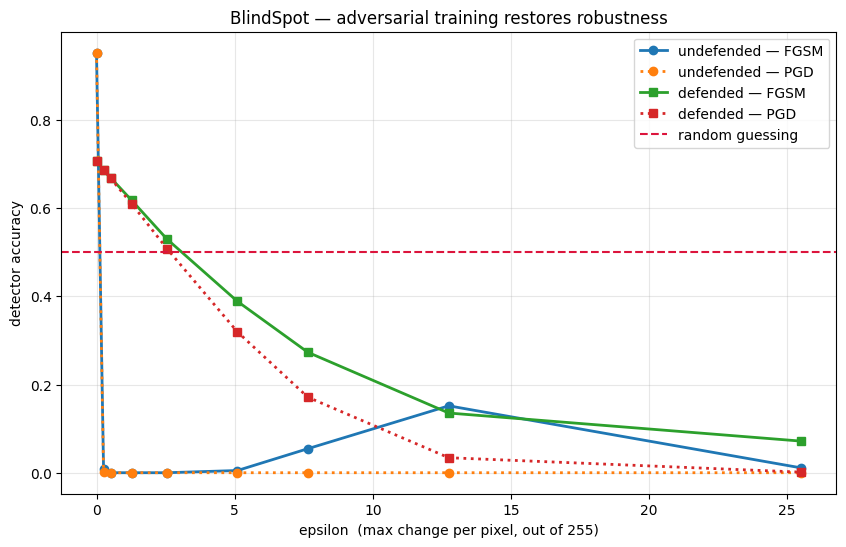

In [4]:
xs = [e*255 for e in EPSILONS]
plt.figure(figsize=(10, 6))
plt.plot(xs, acc_fgsm,      marker="o", lw=2, label="undefended — FGSM")
plt.plot(xs, acc_pgd,       marker="o", lw=2, ls=":", label="undefended — PGD")
plt.plot(xs, acc_def_fgsm,  marker="s", lw=2, label="defended — FGSM")
plt.plot(xs, acc_def_pgd,   marker="s", lw=2, ls=":", label="defended — PGD")
plt.axhline(0.5, color="crimson", ls="--", label="random guessing")
plt.xlabel("epsilon  (max change per pixel, out of 255)")
plt.ylabel("detector accuracy")
plt.title("BlindSpot — adversarial training restores robustness")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("/kaggle/working/defence_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
x_adv2 = fgsm(defended, x, y, EPS)
with torch.no_grad():
    q0 = torch.softmax(defended(x),      1)[0]
    q1 = torch.softmax(defended(x_adv2), 1)[0]

print(f"UNDEFENDED   original {names[p0.argmax()]} ({p0.max():.3f})  ->  attacked {names[p1.argmax()]} ({p1.max():.3f})")
print(f"DEFENDED     original {names[q0.argmax()]} ({q0.max():.3f})  ->  attacked {names[q1.argmax()]} ({q1.max():.3f})")

UNDEFENDED   original fake (0.999)  ->  attacked real (1.000)
DEFENDED     original fake (0.634)  ->  attacked fake (0.569)


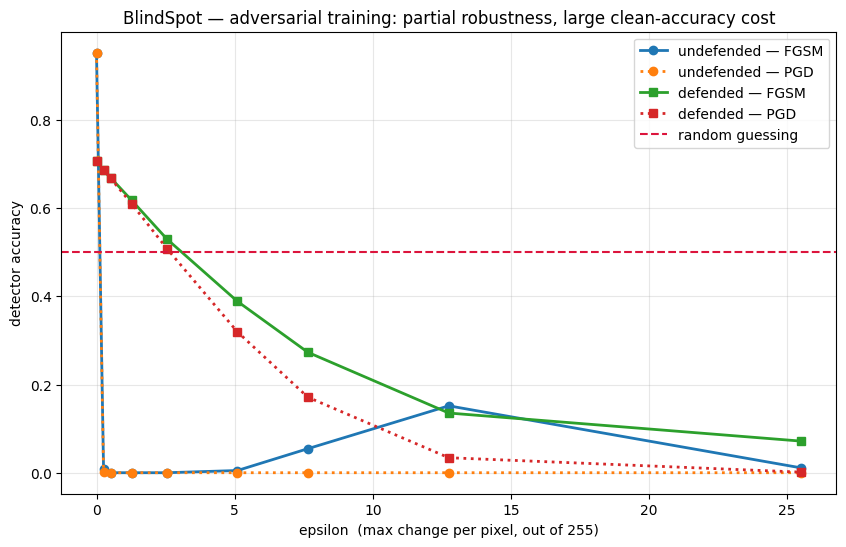

In [1]:
    torch.save(defended.state_dict(), "/kaggle/working/detector_defended_final.pth")

xs = [e*255 for e in EPSILONS]
plt.figure(figsize=(10, 6))
plt.plot(xs, acc_fgsm,     marker="o", lw=2, label="undefended — FGSM")
plt.plot(xs, acc_pgd,      marker="o", lw=2, ls=":", label="undefended — PGD")
plt.plot(xs, acc_def_fgsm, marker="s", lw=2, label="defended — FGSM")
plt.plot(xs, acc_def_pgd,  marker="s", lw=2, ls=":", label="defended — PGD")
plt.axhline(0.5, color="crimson", ls="--", label="random guessing")
plt.xlabel("epsilon  (max change per pixel, out of 255)")
plt.ylabel("detector accuracy")
plt.title("BlindSpot — adversarial training: partial robustness, large clean-accuracy cost")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("/kaggle/working/defence_comparison.png", dpi=150, bbox_inches="tight")
plt.show()